In [1]:
import sys

import cirq
import matplotlib.pyplot as plt

sys.path.append("../")
# import resource_estimation as res
import resource_estimation.ftqc.architecture as arch
import resource_estimation.ftqc.compile_ftqc as comp
import resource_estimation.ftqc.context as ctx
import resource_estimation.ftqc.layout as lyt

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

In [3]:
def plot_layout(layout: lyt.Layout, context: ctx.Context):
    fig, ax = plt.subplots()
    clrs = {
        1: "skyblue",
        2: "gray",
        3: "navy",
        4: "orchid",
        5: "wheat",
    }
    for p in layout.placements.values():
        rect = Rectangle(
            (p.col, p.row),
            width=p.element.footprint.cols,
            height=p.element.footprint.rows,
            edgecolor="black",
            facecolor=clrs[context.roles[p.element.patch_id]],
            alpha=0.5,
        )
        ax.add_patch(rect)
    for p in layout.regions.values():
        rect = Rectangle(
            (p.col, p.row),
            width=p.element.footprint.cols,
            height=p.element.footprint.rows,
            edgecolor="black",
            facecolor="red",
            alpha=0.5,
        )
        ax.add_patch(rect)
        ax.text(
            p.col + p.element.footprint.cols / 2,
            p.row + p.element.footprint.rows / 2,
            str(p.element.role),
            ha="center",
            va="center",
            fontsize=8,
            color="black",
        )
    ax.autoscale_view()
    ax.set_aspect("equal")
    ax.invert_yaxis()  # Row 0 at the top
    # ax.grid(True)
    # plt.show()

In [4]:
q1, q2, q3 = cirq.LineQubit.range(3)
m_circuit = cirq.Circuit(
    cirq.H.on(q1),
    cirq.CCZ.on(q1, q2, q3),
    cirq.S.on(q2),
    cirq.CCZ.on(q1, q2, q3),
    cirq.H.on(q1),
    cirq.CCZ.on(q1, q2, q3),
    cirq.T.on(q1),
    cirq.CNOT.on(q1, q2),
    cirq.measure(q1),
)
l_circuit = cirq.Circuit(
    cirq.H.on(q1),
    cirq.T.on(q1),
    cirq.CNOT.on(q1, q2),
    cirq.measure(q1),
    cirq.S.on(q3),
    cirq.CNOT.on(q3, q1),
)
print(m_circuit)
print("*" * 50)
print(l_circuit)

0: ───H───@───────@───H───@───T───@───M───
          │       │       │       │
1: ───────@───S───@───────@───────X───────
          │       │       │
2: ───────@───────@───────@───────────────
**************************************************
0: ───H───T───@───M───X───
              │       │
1: ───────────X───────┼───
                      │
2: ───S───────────────@───


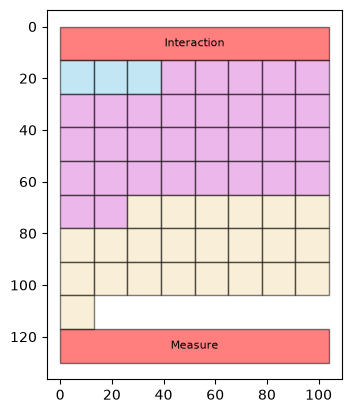

In [5]:
## Movement Keyword Arguments ##
m_dynamic = False
m_surface_code_program_qubits = cirq.num_qubits(m_circuit)
m_surface_code_distance = 7
m_t_cultivation_factories = 0
m_t_distillation_factories = 1
m_ccz_distillation_factories = 1
m_interaction_zone = True
m_measure_zone = True

# This seems like a lot of information just to generate a Layout...
movement_layout = lyt.generate_movement_layout(
    surface_code_program_qubits=m_surface_code_program_qubits,
    surface_code_distance=m_surface_code_distance,
    t_cultivation_factories=m_t_cultivation_factories,
    t_distillation_factories=m_t_distillation_factories,
    ccz_distillation_factories=m_ccz_distillation_factories,
    interaction_zone=m_interaction_zone,
    measure_zone=m_measure_zone,
)
movement_context = ctx.build_movement_context(
    circuit=m_circuit,
    layout=movement_layout,
    t_cultivation_factories=m_t_cultivation_factories,
    t_distillation_factories=m_t_distillation_factories,
    ccz_distillation_factories=m_ccz_distillation_factories,
    dynamic=m_dynamic,
)
movement_arc = arch.DefaultMovement(m_surface_code_distance)
plot_layout(movement_layout, movement_context)

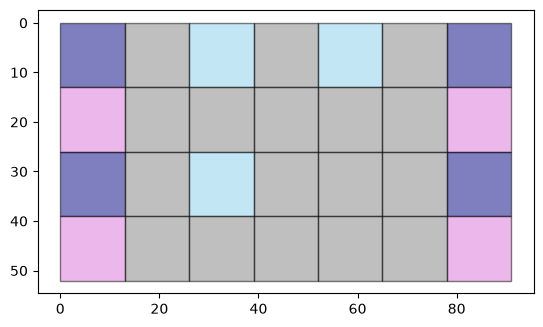

In [6]:
## Lattice Keyword Arguments ##
l_dynamic = False
l_surface_code_program_qubits = cirq.num_qubits(l_circuit)
l_surface_code_distance = 7

# This seems like a lot of information just to generate a Layout...
lattice_layout = lyt.generate_column_layout(
    surface_code_program_qubits=l_surface_code_program_qubits,
    surface_code_distance=l_surface_code_distance,
)
lattice_context = ctx.build_column_context(
    circuit=l_circuit,
    layout=lattice_layout,
    surface_code_distance=l_surface_code_distance,
    dynamic=l_dynamic,
)
lattice_arc = arch.DefaultLattice(l_surface_code_distance)
plot_layout(lattice_layout, lattice_context)

In [7]:
movement_compiled, movement_end_context = comp.ft_compile(
    circuit=m_circuit,
    arc=movement_arc,
    layout=movement_layout,
    context=movement_context,
)

lattice_compiled, lattice_end_context = comp.ft_compile(
    circuit=l_circuit,
    arc=lattice_arc,
    layout=lattice_layout,
    context=lattice_context,
)

[[16, 9], [16, 15], [16, 17], [16, 23]]
[[16, 9, 8], [16, 9, 10], [16, 15, 8], [16, 15, 14], [16, 15, 22], [16, 17, 10], [16, 17, 18], [16, 17, 24], [16, 23, 22], [16, 23, 24]]
Found a path!
[[2, 1], [2, 3], [2, 9]]
[[2, 1, 8], [2, 3, 10], [2, 9, 8], [2, 9, 10]]
[[2, 1, 8, 7], [2, 1, 8, 9], [2, 1, 8, 15], [2, 3, 10, 9], [2, 3, 10, 11], [2, 3, 10, 17], [2, 9, 8, 1], [2, 9, 8, 7], [2, 9, 8, 15], [2, 9, 10, 3], [2, 9, 10, 11], [2, 9, 10, 17]]
Found a path!
[[2, 1], [2, 3], [2, 9]]
[[2, 1, 0], [2, 1, 8], [2, 3, 10], [2, 9, 8], [2, 9, 10]]
Found a path!
[[4, 3], [4, 5], [4, 11]]
[[4, 3, 2], [4, 3, 10], [4, 5, 12], [4, 11, 10], [4, 11, 12], [4, 11, 18]]
Found a path!
[[2, 1], [2, 3], [2, 9]]
[[2, 1, 8], [2, 3, 10], [2, 9, 8], [2, 9, 10], [2, 9, 16]]
Found a path!


In [8]:
movement_compiled

┌──────────────────┐   ┌──────────────────┐   ┌───┐   ┌──────────────────┐   ┌──────────────────┐                                                                                                                                                                                                                                                                                                           ┌───────┐                                                                                                                                                                                                                                                                                                                  ┌──────────────────┐   ┌──────────────────┐   ┌───┐   ┌──────────────────┐   ┌──────────────────┐
0: ───────SE(1)───H─────────────SE(1)───────────────────────────┤0   ├─────────────────X───────┤   1├───────────────────────────────────────SE(1)───H─────────────────────────SE(1)───X─────────────────────────────────┤0   ├────────────@─────────────────┤   1├───SE(1)───┤0   ├────────────@────────────┤   1├───SE(1)───H────────────────────────────────────────────SE(1)────────────┤0   ├───X───┤   1├────────────SE(1)───H───────────────────────────────────────────────SE(1)───X───────────────────────────────────────────────────────────────────────────────────────────────────────────────────┤0   ├────────────@────────────┤   1├───SE(1)───┤0   ├─────────────────@────────────┤   1├───SE(1)───H───────────────────────────────────────SE(1)───H───SE(1)───────────────────────────┤0   ├─────────────────X───────┤   1├───────────────────────────────────────SE(1)───H─────────────────────────SE(1)───X─────────────────────────────────┤0   ├────────────@─────────────────┤   1├───SE(1)───┤0   ├────────────@────────────┤   1├───SE(1)───H───────────────────────────────────────SE(1)────────────┤0   ├───X───┤   1├────────────SE(1)───S─────────────────────────SE(1)───┤0   ├────────────@────────────┤   1├───SE(1)───┤0   ├───M('')───┤   1├───SE(1)───
                                                                                       │                                                                                                                                                  │                                                    │                                                                                                    │                                                                                                                                                                                                                           │                                                    │                                                                                                                                        │                                                                                                                                                  │                                                    │                                                                                               │                                                                                 │
1: ───────SE(1)───────────────────────────────────────────────────────┤0   ├───────────┼X────────────┤   1├─────────────────────────────────SE(1)───H─────────────────────────SE(1)───X──────────────────────────────────────────┤0   ├───X────────┤   1├────────────SE(1)─────────────────────┼─────────────────────────────┤0   ├─────────────────@────────────┤   1├───SE(1)───H─────────────────┼─────────────────────SE(1)───S───────────────────────────────────────────────SE(1)────────────┤0   ├───X───┤   1├────────────SE(1)───H─────────────────────────SE(1)───X──────────────────────────────────────────┤0   ├───X───┤   1├────────────SE(1)──────────────────────────┼─────────────────────────────┤0   ├────────────@────────────┤   1├───SE(1)───H───SE(1)────────────────────────

In [9]:
lattice_compiled

┌─────────────────────┐   ┌───────────────┐   ┌──────────┐                                                           ┌──────────┐   ┌──────────┐
0: ───────SE(7)────H──────────────────────────────MERGE───────────────SPLIT────────────────────────────MERGE───────────SPLIT───Z─────────────#2─────────────#2───────────────M───SE(7)───MERGE───SPLIT───────────────────
                                                  │                   │                                │               │                     │              │                            │       │
1: ───────SE(7)────────────────────MERGE──────────┼────SPLIT──────────┼────────────────────────────────┼───────────────┼─────────────────────┼──────────────┼────────────────────────────┼───────┼───────────────────────
                                   │              │    │              │                                │               │                     │              │                            │       │
2: ───────SE(7)───────────────MERGE┼─────────SPLIT┼────┼─────────Z────┼────────────────────────────────┼───────────────┼─────────────────────┼──────────────┼────────────────────────────┼───────┼───────#2──────#2──────
                              │    │         │    │    │              │                                │               │                     │              │                            │       │       │       │
0-0-3: ────────────CULT(1.571)┼────┼─────────┼────┼────┼──────────────┼────────────────────────────────┼───────────────┼───────#2───────#2───┼─────────M('')┼────────SE(7)───R───────────┼───────┼───────┼───────┼───────
                              │    │         │    │    │              │                                │               │       │        │    │              │                            │       │       │       │
0-1-2: ───────────────────────┼────┼─────────┼────#2───┼──────────────#2───────MERGE───SPLIT───────────#2──────────────#2──────MERGE────SPLIT┼──────────────┼────────────────────────────┼───────┼───────┼───────┼───────
                              │    │         │    │    │              │        │       │                                                     │              │                            │       │       │       │
0-3-2: ───────────────────────┼────#2────────┼────┼────#2─────────────┼────────┼───────┼─────────────────────────────────────────────────────MERGE──────────SPLIT────────────────────────┼───────┼───────┼───────┼───────
                              │              │    │                   │        │       │                                                                                                 │       │       │       │
1-0-4: ────────────CULT(0.785)┼──────────────┼────┼───────────────────┼────────#3──────#3──────────────M('')───SE(7)───R─────────────────────────────────────────────────────────────────┼───────┼───────┼───────┼───────
                              │              │    │                   │        │       │                                                                                                 │       │       │       │
1-1-2: ───────────────────────┼──────────────┼────#3──────────────────#3───────#2──────#2────────────────────────────────────────────────────────────────────────────────────────────────┼───────┼───────┼───────┼───────
                              │              │                                                                                                                                           │       │       │       │
1-2-2: ───────────────────────┼──────────────┼───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────#2──────#2──────MERGE───SPLIT───
                              │              │
2-0-3: ────────────CULT(1.571)┼──────────────┼───────────────────#2────────────#2──────M('')───SE(7)───R──────────────────────────────────────────────────────────────────────────────────────

In [10]:
import resource_estimation.analysis as ans
import resource_estimation.ftqc.estimate as est

In [11]:
estimator = est.ResourceEstimator(arc=movement_arc)
gate_cost = estimator.parallel_circuit_cost(
    movement_compiled, layout=movement_layout, context=movement_end_context
)
pretty_gate_cost = {ans.make_pretty(key): val for key, val in gate_cost.items()}
circuit_time = estimator.parallel_circuit_time(
    movement_compiled, layout=movement_layout, context=movement_end_context
)
physical_qubits = estimator.physical_qubits(movement_compiled)

In [12]:
print("Gates")
for op, count in sorted(gate_cost.items(), key=lambda x: x[1], reverse=True):
    op = ans.make_pretty(op)
    print(f"{op}{' ' * (25 - len(op))}{count:.2e}")
print("*" * 33)
print("Metrics")
print(f"Time (μs){' ' * 16}{circuit_time:.2e}\nQubits{' ' * 19}{physical_qubits:.2e}")

Gates
MovementGate             1.02e+03
CZ                       3.76e+02
PhasedXZGate             1.50e+02
MeasurementGate          5.60e+01
ResetChannel             5.50e+01
*********************************
Metrics
Time (μs)                6.28e+05
Qubits                   7.08e+03


In [13]:
estimator = est.ResourceEstimator(arc=lattice_arc)
gate_cost = estimator.parallel_circuit_cost(
    lattice_compiled, layout=lattice_layout, context=lattice_end_context
)
pretty_gate_cost = {ans.make_pretty(key): val for key, val in gate_cost.items()}
circuit_time = estimator.parallel_circuit_time(
    lattice_compiled, layout=lattice_layout, context=lattice_end_context
)
physical_qubits = estimator.physical_qubits(lattice_compiled)

In [14]:
print("Gates")
for op, count in sorted(gate_cost.items(), key=lambda x: x[1], reverse=True):
    op = ans.make_pretty(op)
    print(f"{op}{' ' * (25 - len(op))}{count:.2e}")
print("*" * 33)
print("Metrics")
print(f"Time (μs){' ' * 16}{circuit_time:.2e}\nQubits{' ' * 19}{physical_qubits:.2e}")

Gates
CZ                       2.80e+02
PhasedXZGate             1.41e+02
MeasurementGate          7.30e+01
ResetChannel             7.20e+01
*********************************
Metrics
Time (μs)                1.03e+05
Qubits                   1.07e+03
